# Homework 5: Statistical Hypothesis Testing (Chi-Square & ANOVA)


## Dataset Setup Instructions

To complete this assignment, download **IBM HR Analytics Employee Attrition & Performance Dataset** from github or kaggle.


### Part 1: Chi-Square Test of Independence (Categorical vs. Categorical)
1. Formulate a research question examining whether two workforce attributes are associated (e.g., *Is an employee's Department associated with their likelihood of working OverTime? Is Gender associated with different Job Roles?*).
2. State your Null Hypothesis ($H_0$) and Alternative Hypothesis ($H_1$).
3. Compute a contingency table showing the exact cross-tabulated counts of employees across these categories.
4. Execute a Chi-Square Test of Independence at a 5% significance level ($\alpha = 0.05$). Report the test statistic, degrees of freedom, and the p-value.
5. Create a grouped or stacked bar chart to visually compare the proportional distribution between the groups.
6. Write 2–3 sentences interpreting what these findings mean for an HR manager trying to address workplace imbalances.

---

### Part 2: One-Way ANOVA (Numerical Continuous vs. Categorical with >2 Groups)
1. Formulate a research question evaluating whether average compensation scales vary across different structural groups (e.g., *Does the mean MonthlyIncome differ significantly across the 3 distinct Departments? Does it differ based on MaritalStatus?*).
2. State your Null Hypothesis ($H_0$) and Alternative Hypothesis ($H_1$).
3. Run a One-Way ANOVA test at a 5% significance level ($\alpha = 0.05$). Report the F-statistic and the p-value.
4. Generate a boxplot or violin plot displaying `MonthlyIncome` across the different categorical groups.
5. Write 2–3 sentences interpreting your statistical conclusions. If the test is significant, note which specific groups appear to stand out.

---

## Part 3: Assessing Decision Errors in HR Policy
Select **either** your Chi-Square test or your ANOVA test from Part 1 or 2. For that specific test, write a brief analysis detailing:
1. Exactly what a Type I error (false positive) translates to in the context of your specific workplace hypothesis.
2. Exactly what a Type II error (false negative) translates to in the context of your specific workplace hypothesis.
3. From a corporate governance, budget planning, or employee retention standpoint, explain which of these two errors carries a worse operational risk for the company, and why.



In [50]:
import numpy as np
import pandas as pd
import scipy.stats as stats
import pingouin as pg
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import chisquare, chi2_contingency
from scipy.stats import f_oneway
from sklearn.preprocessing import LabelEncoder 
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

## Is  Gender Associated with People's Likelihood of Dying from a Disease?

## H0 = Gender is Associated with the Likelihood of Dying from a Disease
## H1 = Gender is Not Associated with the Likelihood of Dying from a Disease

In [13]:
df = pd.read_csv("New_York_City_Leading_Causes_of_Death.csv")

In [64]:
mapping = {'M': 'Male', 'F': 'Female'}
df['Sex'] = df['Sex'].map(mapping)

df.tail() 

#getting rid of M and F values in Sex otherwise my data gets jumbled 

,Year,Leading Cause,Sex,Race Ethnicity,Deaths,Death Rate,Age Adjusted Death Rate
2097,2021,Essential Hypertension and Renal Diseases (I10...,NaN,Not Stated/Unknown,10,NaN,NaN
2098,2021,Human Immunodeficiency Viruses Diseases,NaN,Not Stated/Unknown,7,NaN,NaN
2099,2021,Diabetes Mellitus (E10-E14),NaN,Not Stated/Unknown,7,NaN,NaN
2100,2021,Alzheimer's Disease (G30),NaN,Not Stated/Unknown,7,NaN,NaN
2101,2021,All Other Causes,NaN,Not Stated/Unknown,102,NaN,NaN


In [66]:
ctable = pd.crosstab(df["Sex"], df["Deaths"])
print(ctable)
chi2, p, dof, expected = chi2_contingency(ctable)
alpha = 0.05

print("\nChi-square statistic:", chi2)
print("Degrees of freedom:", dof)
print("p-value:", p)
print("\nExpected Frequencies:\n", expected)


#tstat, pvalue = stats.ttest_ind(df['Sex'], df['Deaths'])

#print(f"T-statistic: {tstat}")
#print(f"P-value: {pvalue}")

#if pvalue <0.05:
#    print("Reject H0: Gender is Not Associated with the Likelihood of Dying from a Disease")
#else:
 #   print("Gender is Associated with the Likelihood of Dying from a Disease") 
    
    #Unable to Fix pvalue and fstat calculation error

Deaths   .  10  1007  101  1013  102  1025  103  104  1045  ...  91  92  93  \
Sex                                                         ...               
Female  91   5     1    1     0    2     1    1    1     1  ...   0   0   1   
Male    47  12     0    0     1    2     0    1    0     0  ...   1   2   0   

Deaths  94  95  96  969  98  988  99  
Sex                                   
Female   1   2   1    1   1    0   0  
Male     2   1   3    0   0    1   3  

[2 rows x 508 columns]

Chi-square statistic: 525.226414603798
Degrees of freedom: 507
p-value: 0.2787582415090032

Expected Frequencies:
 [[69.72867587  8.58976442  0.50528026 ...  0.50528026  0.50528026
   1.51584078]
 [68.27132413  8.41023558  0.49471974 ...  0.49471974  0.49471974
   1.48415922]]


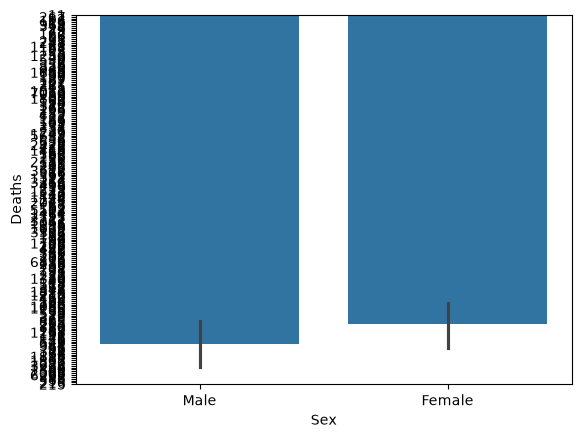

In [69]:
chart = sns.barplot(data=df, x= 'Sex', y= 'Deaths', legend=True)

### These findings display that there is a statistical difference between the amount of deaths in males and females in New York. This also means that diseases are far more fatal to men than women

## Step 2

## Does the mean Employment Change between 2023-2033 Differ between Industry Types?

## H0 = Mean Employment Differs Between Industry Types
## H1 = Mean Employment Does Not Differ Between Industry Types

In [31]:
df2 = pd.read_csv("National Employment_dataBLSgov_projections.csv")

In [32]:
df2.head()

,Industry Title,Industry Code,Industry Type,2023 Employment,2023 Percent of Occupation,2023 Percent of Industry,Projected 2033 Employment,Projected 2033 Percent of Occupation,Projected 2033 Percent of Industry,"Employment Change, 2023-2033","Employment Percent Change, 2023-2033",Industry Sort,Display Level
0,Total employment,TE1000,Summary,544.4,100.0,0.3,554.5,100.0,0.3,10.1,1.9,NaN,0
1,Self-employed workers,TE1100,Line Item,289.2,53.1,3.0,285.6,51.5,2.9,-3.6,-1.2,2.0,1
2,Total wage and salary employment,TE1200,Summary,255.2,46.9,0.2,268.9,48.5,0.2,13.7,5.4,3.0,1
3,"Mining, quarrying, and oil and gas extraction",210000,Summary,2.2,0.4,0.4,2.2,0.4,0.4,-0.1,-3.3,12.0,2
4,Oil and gas extraction,211000,Line Item,1.7,0.3,1.5,1.6,0.3,1.5,-0.1,-5.2,13.0,3


In [53]:
anova = pg.anova(data=df2, dv='Employment Change, 2023-2033', between='Industry Type', detailed = True)
print(anova,'\n')
groups = [group["Employment Change, 2023-2033"].values for name, group in df2.groupby("Industry Type")]

f_stat, p_value = stats.f_oneway(*groups)

print("F-statistic:", f_stat)
print("p-value:", p_value)

if p_value <0.05:
    print("Reject H0: Mean Employment Does Not Differ Between Industry Types")
else:
    print("Failed to reject H0: Mean Employment Differs Between Industry Types")

          Source          SS  DF        MS         F     p_unc       np2
0  Industry Type    2.811074   1  2.811074  0.420899  0.518301  0.005107
1         Within  547.655950  82  6.678731       NaN       NaN       NaN 

F-statistic: 0.42089940828651373
p-value: 0.5183014528053668
Failed to reject H0: Mean Employment Differs Between Industry Types


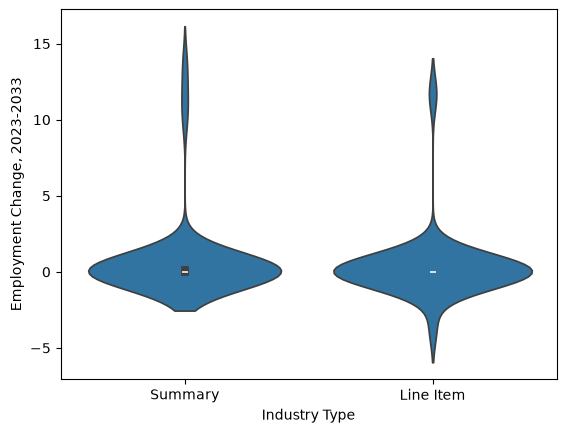

In [55]:
sns.violinplot(data=df2, x="Industry Type", y="Employment Change, 2023-2033")
plt.show()


### These findings from the graph display that a lot of data in both industry types are clustered near the zero mark, but the upper ends each differing. Summary industry type being slightly longer than Line Item industry type. This is also supplemented by the hypothesis test calculating the H0 not being rejected. This means that depending on the industry type, mean employment differs.

## Part 3

## 1. A Type 1 error for my 2nd data analysis would suggest that there is no difference in mean employment depending on your industry type when there is  
## 2. A Type 2 error for my 2nd data analysis would suggest that there is a difference in mean employment depending on industry type when there in fact isn't
## 3. I think a false positive would impact a business a lot for my 2nd data analysis. I think this because if it were to come out that there is a difference in employment rate based on industry type when people were told that there isn't, it would seem as if they were lied to and would put an industry under backlash from the public.